# 💳 Anomaly Detection in Credit Card Transactions

**Goal:** detect potentially fraudulent credit card transactions using **unsupervised learning only**,
that is, without ever showing the fraud labels to the models.

**Dataset:** [Credit Card Fraud Detection (Kaggle, ULB)](https://www.kaggle.com/datasets/mlg-ulb/creditcardfraud):
284,807 transactions made by European cardholders over two days in September 2013.
- `V1` … `V28`: anonymised features. The bank already transformed the original data with PCA to protect privacy.
- `Time`: seconds elapsed since the first transaction in the dataset.
- `Amount`: transaction amount (€).
- `Class`: **1 = fraud, 0 = normal**. This label is **hidden** from all models and used **only for evaluation**.

### The golden rule of this notebook
> The `Class` column is put aside before modelling. No model is trained on it, no hyperparameter
> is tuned with it, and every decision threshold is chosen without it. The labels come back only in
> the **Evaluation** section, to check how well the unsupervised models found the frauds.

### Pipeline
1. **Data exploration**: distributions of `Amount` and `Time`, class imbalance, patterns
2. **Preprocessing**: feature engineering, scaling, PCA / t-SNE visualisation
3. **Unsupervised models**: Isolation Forest, One-Class SVM, Autoencoder (PyTorch), plus a simple ensemble
4. **Evaluation**: reveal the labels; precision, recall, F1, PR-AUC, ROC-AUC
5. **Insights**: which transactions were flagged, and what the detected anomalies have in common
6. **Conclusions**

## 0. Setup

In [1]:
import os
import time
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, MinMaxScaler
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
from sklearn.ensemble import IsolationForest
from sklearn.svm import OneClassSVM
from sklearn.metrics import (
    precision_score, recall_score, f1_score, classification_report, confusion_matrix,
    roc_auc_score, average_precision_score, precision_recall_curve, roc_curve,
)

import torch
import torch.nn as nn
from torch.utils.data import DataLoader, TensorDataset

warnings.filterwarnings("ignore")

SEED = 42
np.random.seed(SEED)
torch.manual_seed(SEED)

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.dpi"] = 100
NORMAL_C, FRAUD_C = "#4C72B0", "#D1495B"
MODEL_COLORS = {"Distance baseline": "#9E9E9E", "Isolation Forest": "#2A9D8F", "One-Class SVM": "#E9C46A",
                "Autoencoder": "#8E5EA2", "Ensemble": "#264653"}

## 1. Load the data
The CSV is about 150 MB, which is larger than GitHub's 100 MB file limit, so it is **not** stored in the repository.
The cell below downloads it automatically from Kaggle with `kagglehub` the first time it runs.

In [2]:
DATA_PATH = os.path.join("data", "creditcard.csv")

if not os.path.exists(DATA_PATH):
    import kagglehub, shutil
    os.makedirs("data", exist_ok=True)
    src = kagglehub.dataset_download("mlg-ulb/creditcardfraud")
    shutil.copy(os.path.join(src, "creditcard.csv"), DATA_PATH)

df = pd.read_csv(DATA_PATH)
print(f"Shape: {df.shape[0]:,} rows x {df.shape[1]} columns")
df.head()

Shape: 284,807 rows x 31 columns


,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0.0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,...,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,149.62,0
1,0.0,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,...,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,2.69,0
2,1.0,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,...,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,378.66,0
3,1.0,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,...,-0.108300,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,123.50,0
4,2.0,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,0.817739,...,-0.009431,0.798278,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153,69.99,0


## 2. Data exploration

### 2.1 Data quality: types, missing values, duplicates

In [3]:
print("Column types:", df.dtypes.value_counts().to_dict())
print("Missing values:", int(df.isna().sum().sum()))
print("Duplicated rows:", int(df.duplicated().sum()))
df[["Time", "Amount"]].describe().T

Column types: {dtype('float64'): 30, dtype('int64'): 1}
Missing values: 0


Duplicated rows: 1081


,count,mean,std,min,25%,50%,75%,max
Time,284807.0,94813.859575,47488.145955,0.0,54201.5,84692.0,139320.500,172792.00
Amount,284807.0,88.349619,250.120109,0.0,5.6,22.0,77.165,25691.16


- All columns are numeric and there are **no missing values**, so no imputation is needed.
- About 1,000 rows are exact duplicates. In real card data the same purchase can legitimately be repeated
  (e.g. two identical coffees), so I **keep** them.
- `Amount` is very skewed: the median is about €22 but the maximum is above €25,000.

### 2.2 Class imbalance
*(This is the only place before Evaluation where the labels are looked at. It is done to understand
the problem, and nothing learned here is fed into the models.)*

         count  percent
Class                  
Normal  284315   99.827
Fraud      492    0.173


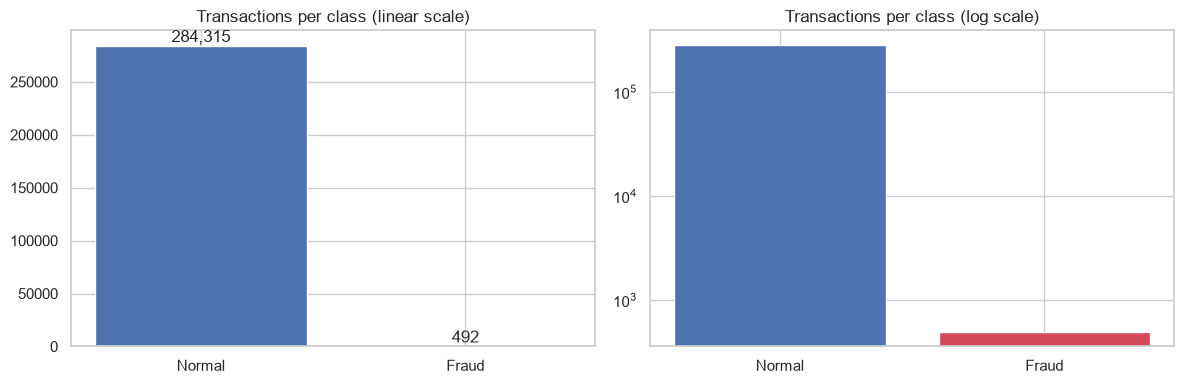

In [4]:
counts = df["Class"].value_counts().sort_index()
pct = counts / counts.sum() * 100
print(pd.DataFrame({"count": counts, "percent": pct.round(3)}).rename(index={0: "Normal", 1: "Fraud"}))

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].bar(["Normal", "Fraud"], counts.values, color=[NORMAL_C, FRAUD_C])
ax[0].set_title("Transactions per class (linear scale)")
for i, v in enumerate(counts.values):
    ax[0].text(i, v, f"{v:,}", ha="center", va="bottom")
ax[1].bar(["Normal", "Fraud"], counts.values, color=[NORMAL_C, FRAUD_C])
ax[1].set_yscale("log")
ax[1].set_title("Transactions per class (log scale)")
plt.tight_layout(); plt.show()

**Extremely imbalanced:** only **492 frauds out of 284,807 transactions (≈0.17 %)**.
- **Accuracy is useless here.** A model that says "normal" every time is 99.83 % accurate and catches zero frauds.
  We will focus on **precision, recall, F1 and the area under the precision-recall curve (PR-AUC)**.
- The imbalance is also why **anomaly detection** fits: frauds are *rare* and, we hope, *different*, which are
  exactly the two assumptions unsupervised anomaly detectors rely on.

### 2.3 Distribution of `Amount`

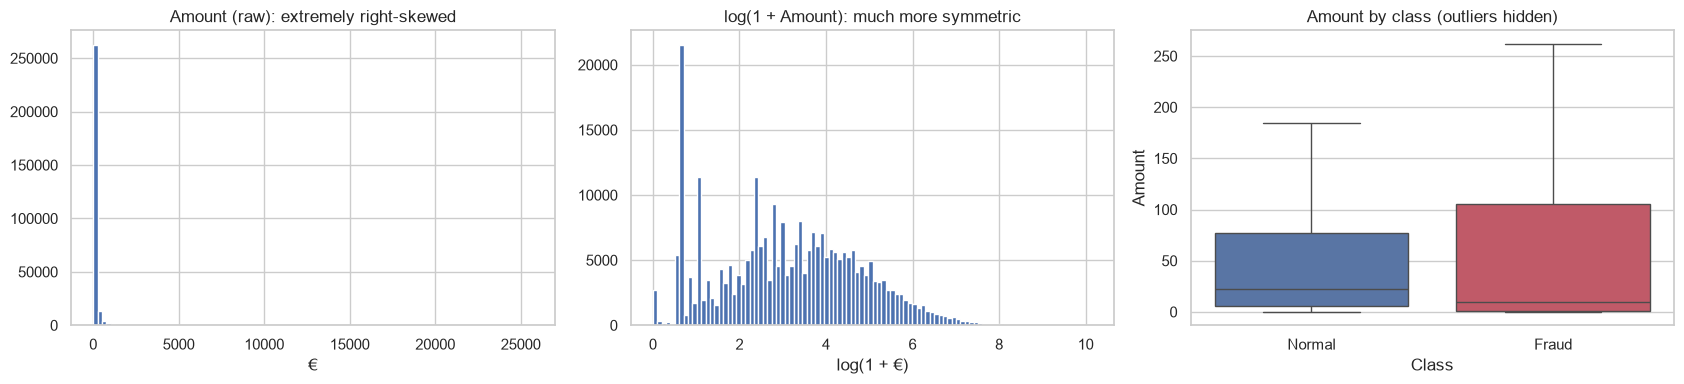

,count,mean,std,min,25%,50%,75%,max
Class,,,,,,,,
Normal,284315.0,88.29,250.11,0.0,5.65,22.00,77.05,25691.16
Fraud,492.0,122.21,256.68,0.0,1.00,9.25,105.89,2125.87


In [5]:
fig, ax = plt.subplots(1, 3, figsize=(17, 4))
ax[0].hist(df["Amount"], bins=100, color=NORMAL_C)
ax[0].set_title("Amount (raw): extremely right-skewed"); ax[0].set_xlabel("€")
ax[1].hist(np.log1p(df["Amount"]), bins=100, color=NORMAL_C)
ax[1].set_title("log(1 + Amount): much more symmetric"); ax[1].set_xlabel("log(1 + €)")
sns.boxplot(data=df, x="Class", y="Amount", ax=ax[2], palette=[NORMAL_C, FRAUD_C], showfliers=False)
ax[2].set_xticklabels(["Normal", "Fraud"]); ax[2].set_title("Amount by class (outliers hidden)")
plt.tight_layout(); plt.show()

df.groupby("Class")["Amount"].describe().rename(index={0: "Normal", 1: "Fraud"}).round(2)

- `Amount` follows a long-tail distribution. Most transactions are small and a few are huge. A **log transform**
  makes it much better behaved, so I will use `log(1 + Amount)` as a feature.
- Frauds are **not** typically large: their median is lower than for normal transactions, and many are tiny
  amounts (≈ €1), which looks like card testing. Their spread is wide, though. **Amount alone cannot separate fraud.**

### 2.4 Distribution of `Time`

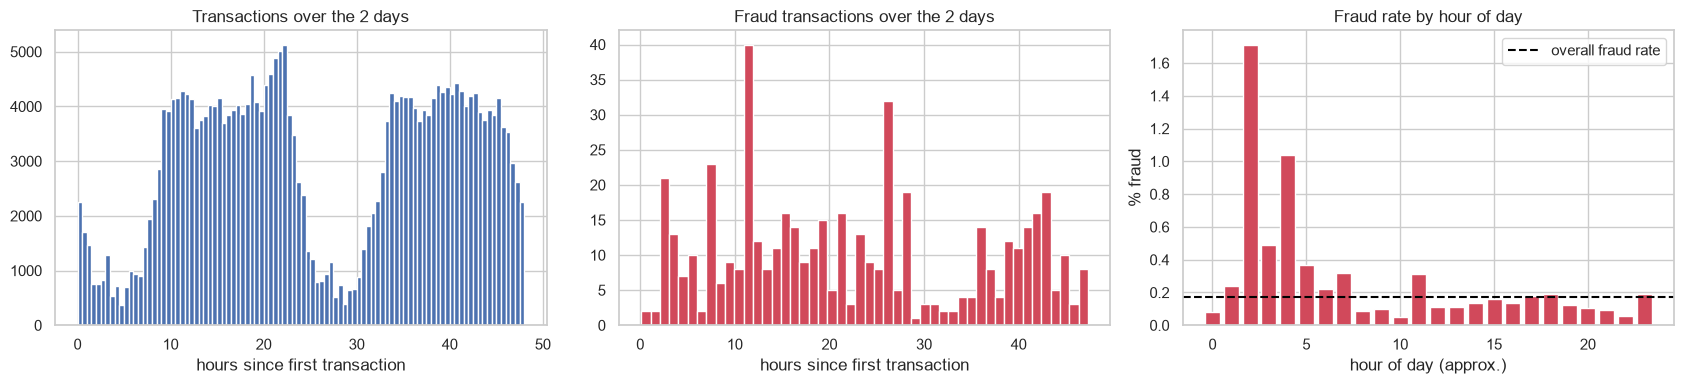

In [6]:
hours = df["Time"] / 3600
df_hour = (df["Time"] // 3600 % 24).astype(int)

fig, ax = plt.subplots(1, 3, figsize=(17, 4))
ax[0].hist(hours, bins=96, color=NORMAL_C)
ax[0].set_title("Transactions over the 2 days"); ax[0].set_xlabel("hours since first transaction")
ax[1].hist(hours[df["Class"] == 1], bins=48, color=FRAUD_C)
ax[1].set_title("Fraud transactions over the 2 days"); ax[1].set_xlabel("hours since first transaction")
fraud_rate_by_hour = df.groupby(df_hour)["Class"].mean() * 100
ax[2].bar(fraud_rate_by_hour.index, fraud_rate_by_hour.values, color=FRAUD_C)
ax[2].axhline(df["Class"].mean() * 100, color="black", ls="--", label="overall fraud rate")
ax[2].set_title("Fraud rate by hour of day"); ax[2].set_xlabel("hour of day (approx.)"); ax[2].set_ylabel("% fraud")
ax[2].legend()
plt.tight_layout(); plt.show()

- Normal activity has a clear **day/night cycle**: two daytime peaks with a deep dip at night.
- Frauds are spread much more **evenly** across time. They do not follow the human daily rhythm.
- So the **fraud rate is highest during the night hours (≈ 2-4 am)**, when legitimate activity is low.
  The raw `Time` value (seconds since the start) means nothing on its own, but the **hour of day** does.
  I will encode it as a cyclic feature.

### 2.5 The PCA features `V1`-`V28`

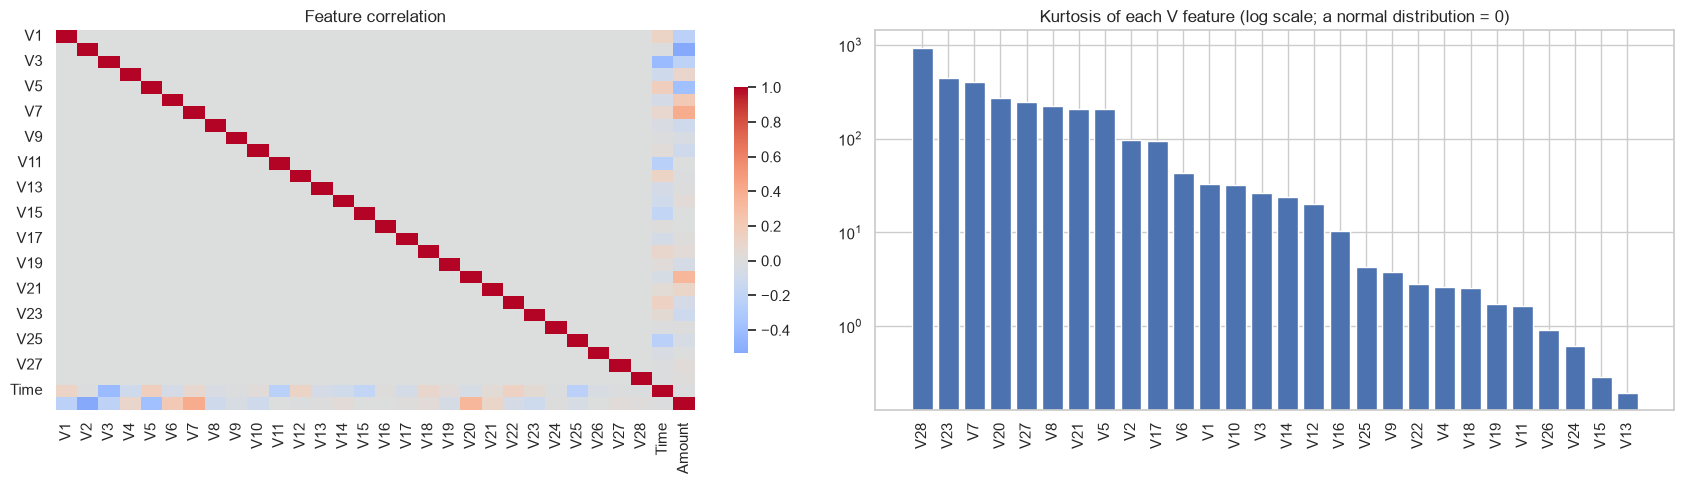

In [7]:
v_cols = [f"V{i}" for i in range(1, 29)]
fig, ax = plt.subplots(1, 2, figsize=(17, 5))
corr = df[v_cols + ["Time", "Amount"]].corr()
sns.heatmap(corr, cmap="coolwarm", center=0, ax=ax[0], cbar_kws={"shrink": .7})
ax[0].set_title("Feature correlation")
kurt = df[v_cols].kurtosis().sort_values(ascending=False)
ax[1].bar(kurt.index, kurt.values, color=NORMAL_C)
ax[1].set_yscale("log"); ax[1].tick_params(axis="x", rotation=90)
ax[1].set_title("Kurtosis of each V feature (log scale; a normal distribution = 0)")
plt.tight_layout(); plt.show()

- `V1`-`V28` are **uncorrelated with each other**, as expected for principal components. Only `Amount` and `Time`
  correlate with some of them.
- Many V features have **very heavy tails** (high kurtosis): most values sit near 0 with rare, extreme values far away.
  Those rare extremes are what our anomaly detectors will look for. This also matters for choosing a scaler (next section).

## 3. Preprocessing

### 3.1 Hide the labels and engineer features
- `Class` is moved into `y` and **removed from the feature matrix**.
- `Time` → **hour of day**, encoded as `sin`/`cos` so that 23:00 and 00:00 end up close together.
- `Amount` → `log(1 + Amount)` to tame the long tail.

In [8]:
y = df["Class"].values                         # HIDDEN, used only in Section 5 (Evaluation)
X = df.drop(columns=["Class"]).copy()

hour = (X["Time"] // 3600) % 24
X["Hour_sin"] = np.sin(2 * np.pi * hour / 24)
X["Hour_cos"] = np.cos(2 * np.pi * hour / 24)
X["Amount_log"] = np.log1p(X["Amount"])
X = X.drop(columns=["Time", "Amount"])

feature_names = X.columns.tolist()
print(f"{len(feature_names)} features:", feature_names)

31 features: ['V1', 'V2', 'V3', 'V4', 'V5', 'V6', 'V7', 'V8', 'V9', 'V10', 'V11', 'V12', 'V13', 'V14', 'V15', 'V16', 'V17', 'V18', 'V19', 'V20', 'V21', 'V22', 'V23', 'V24', 'V25', 'V26', 'V27', 'V28', 'Hour_sin', 'Hour_cos', 'Amount_log']


### 3.2 Train / test split
The models are fitted on 70 % of the transactions. The remaining 30 % is held out, scored, and used for evaluation.
The split is **random and not stratified**, because stratifying would require the labels.
The training set therefore contains some frauds that nobody knows about, which is exactly what happens in real life.

In [9]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=SEED)
print(f"Train: {len(X_train):,} rows | Test: {len(X_test):,} rows")
print(f"(Hidden) frauds in test set: {y_test.sum()} ({y_test.mean()*100:.3f} %)")

Train: 199,364 rows | Test: 85,443 rows
(Hidden) frauds in test set: 136 (0.159 %)


### 3.3 Scaling: MinMaxScaler or StandardScaler?
Scaling matters for distance and gradient based models (One-Class SVM, Autoencoder). `MinMaxScaler` is a common
default choice, so let's first check how it behaves on these heavy-tailed features.

In [10]:
mm = MinMaxScaler().fit(X_train)
X_mm = pd.DataFrame(mm.transform(X_train), columns=feature_names)
# How much of the [0, 1] range do the central 98% of the values actually use?
spread = (X_mm.quantile(0.99) - X_mm.quantile(0.01)).sort_values()
print("Width of the central 98% of values after MinMax scaling (out of a range of 1.0):")
print(spread.head(8).round(3).to_string())

Width of the central 98% of values after MinMax scaling (out of a range of 1.0):
V28    0.029
V7     0.035
V23    0.040
V20    0.042
V5     0.044
V27    0.053
V21    0.055
V6     0.064


With `MinMaxScaler`, a single extreme value defines the whole range. For many features, **98 % of the transactions
get squeezed into a tiny sliver of [0, 1]**, so the "normal" structure becomes almost invisible to distance-based
models. **`StandardScaler`** (zero mean, unit variance) does not have this problem and also suits the neural network,
so I use it. Importantly, the scaler is **fitted on the training set only** to avoid leaking information from the test set.

In [11]:
scaler = StandardScaler().fit(X_train)
X_train_s = scaler.transform(X_train).astype(np.float32)
X_test_s = scaler.transform(X_test).astype(np.float32)
print("Scaled train mean ≈", X_train_s.mean().round(4), "| std ≈", X_train_s.std().round(4))

Scaled train mean ≈ -0.0 | std ≈ 1.0


### 3.4 Visualisation with PCA and t-SNE
The data has 31 dimensions, so I project it to 2-D to see whether frauds look different.
Labels are used **only to colour the points**. PCA and t-SNE themselves never see them.

t-SNE took 102s


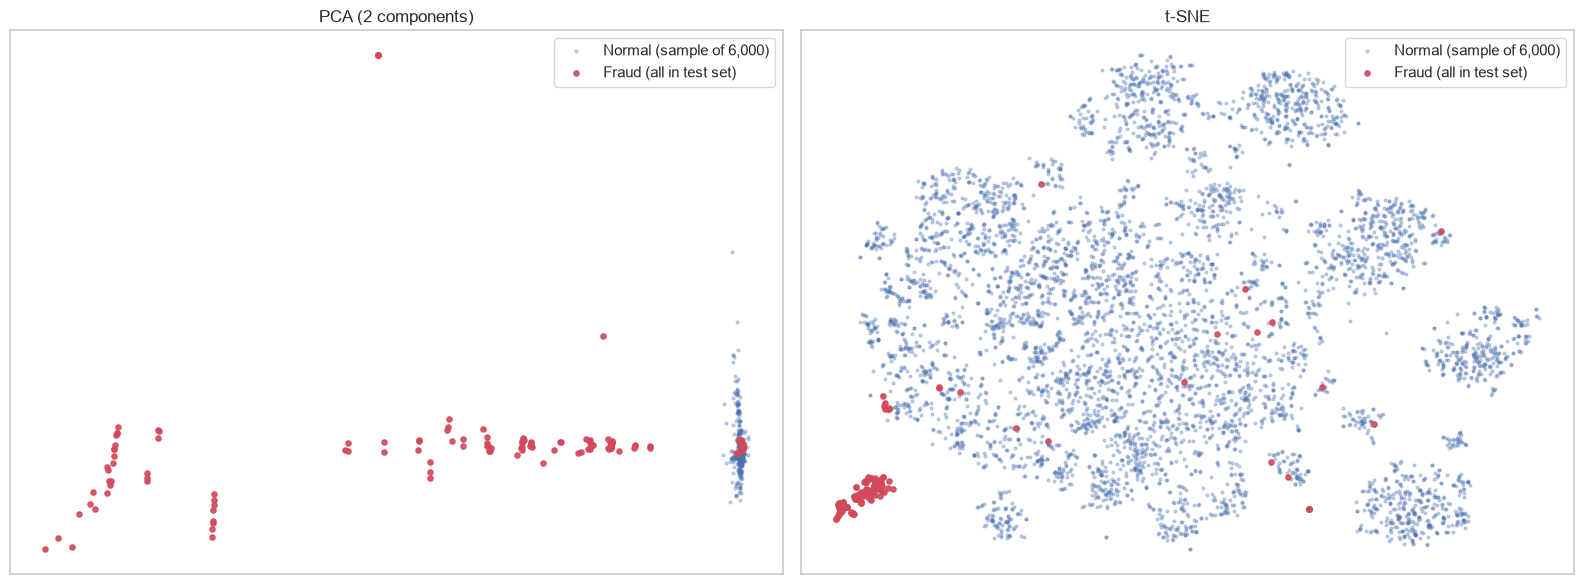

In [12]:
rng = np.random.default_rng(SEED)
normal_idx = rng.choice(np.where(y_test == 0)[0], 6000, replace=False)
fraud_idx = np.where(y_test == 1)[0]
viz_idx = np.concatenate([normal_idx, fraud_idx])
X_viz, y_viz = X_test_s[viz_idx], y_test[viz_idx]

pca_2d = PCA(n_components=2, random_state=SEED).fit_transform(X_viz)
t0 = time.time()
tsne_2d = TSNE(n_components=2, perplexity=40, init="pca", random_state=SEED).fit_transform(X_viz)
print(f"t-SNE took {time.time()-t0:.0f}s")

fig, ax = plt.subplots(1, 2, figsize=(16, 6))
for a, emb, title in [(ax[0], pca_2d, "PCA (2 components)"), (ax[1], tsne_2d, "t-SNE")]:
    a.scatter(emb[y_viz == 0, 0], emb[y_viz == 0, 1], s=4, alpha=.3, c=NORMAL_C, label="Normal (sample of 6,000)")
    a.scatter(emb[y_viz == 1, 0], emb[y_viz == 1, 1], s=14, alpha=.9, c=FRAUD_C, label="Fraud (all in test set)")
    a.set_title(title); a.legend(loc="best"); a.set_xticks([]); a.set_yticks([])
plt.tight_layout(); plt.show()

- In **PCA**, most normal transactions form a dense core, and many frauds lie **on the edges or outside it**.
- **t-SNE** shows this even more clearly: a large group of frauds forms its own tight cluster, away from all normal points.
  But some frauds sit **inside** the normal clusters. Those will be very hard for any unsupervised method to find.

This is encouraging: a large share of frauds really are *"few and different"*.

## 4. Unsupervised anomaly detection models
Each model outputs an **anomaly score** for every transaction (higher = more suspicious). None of them sees `y`.

### How do we turn a score into a "fraud / not fraud" decision without labels?
We set an **alert budget**: *"flag the top X % most anomalous transactions for review"*. This is how fraud teams
actually work, because they have a limited number of analysts. The threshold is the score's (1 − X) quantile
**on the training set**, then applied to the test set.

My main operating point is **X = 0.2 %**, chosen from domain knowledge (card fraud rates are typically around
0.1-0.2 % of transactions), not from the labels. Section 5 also shows results for a range of budgets, so the
conclusions do not depend on this single choice.

In [13]:
PRIMARY_BUDGET = 0.002
BUDGETS = [0.001, 0.002, 0.005, 0.01, 0.02, 0.05]

scores = {}  # model name -> (train_scores, test_scores)

def flag(train_scores, test_scores, budget):
    # Flag test transactions whose score is above the (1 - budget) quantile of the training scores.
    threshold = np.quantile(train_scores, 1 - budget)
    return (test_scores >= threshold).astype(int)

### 4.0 Naive baseline: distance from the average transaction
Before training anything clever, I need a simple reference point. After standardisation the "average" transaction
sits at the origin, so the baseline score is just **how far a transaction is from that average**
(its mean squared standardised value). A model is only worth using if it beats this.

In [14]:
scores["Distance baseline"] = ((X_train_s ** 2).mean(axis=1), (X_test_s ** 2).mean(axis=1))

### 4.1 Isolation Forest
**Idea:** build many random trees that split the data on random features at random values. Anomalies are
*few and different*, so they get **isolated after only a few splits** (short path length), while normal points
are buried deep inside the trees. The anomaly score comes from the average path length.
- Fast, scales well, and needs no distance computations, so it is a strong baseline for tabular data.

In [15]:
t0 = time.time()
iso = IsolationForest(n_estimators=300, max_samples=256, contamination="auto",
                      random_state=SEED, n_jobs=-1)
iso.fit(X_train_s)
# score_samples: higher = more normal, so negate it to get "higher = more anomalous"
scores["Isolation Forest"] = (-iso.score_samples(X_train_s), -iso.score_samples(X_test_s))
print(f"Isolation Forest trained and scored in {time.time()-t0:.1f}s")

Isolation Forest trained and scored in 12.9s


### 4.2 One-Class SVM
**Idea:** use the RBF kernel to map the data into a high-dimensional space and learn a boundary that encloses
most of the training data. Points outside the boundary are anomalies. `nu` is roughly the fraction of training
points allowed outside it.
- Its training cost grows roughly **quadratically** with the number of samples, so it is trained on a random
  subsample of 20,000 training transactions. This is standard practice, and the boundary of "normal" is already well captured.

In [16]:
t0 = time.time()
sub = np.random.default_rng(SEED).choice(len(X_train_s), 20_000, replace=False)
ocsvm = OneClassSVM(kernel="rbf", gamma="scale", nu=0.01)
ocsvm.fit(X_train_s[sub])
# decision_function: positive = inside (normal), so negate it
scores["One-Class SVM"] = (-ocsvm.decision_function(X_train_s), -ocsvm.decision_function(X_test_s))
print(f"One-Class SVM trained and scored in {time.time()-t0:.1f}s "
      f"({ocsvm.support_vectors_.shape[0]:,} support vectors)")

One-Class SVM trained and scored in 46.8s (592 support vectors)


### 4.3 Autoencoder (PyTorch)
**Idea:** a neural network learns to **compress** each transaction into a small code (8 numbers) and then **rebuild** it.
Because almost all of the training data is normal, the network becomes good at rebuilding *normal* patterns.
An unusual transaction gets rebuilt badly, so its **reconstruction error is the anomaly score**.

Architecture: `31 → 16 → 8 → 16 → 31` with ReLU activations, trained with MSE loss and the Adam optimiser.
10 % of the training set is kept apart to monitor the validation loss (still unlabelled data).

epoch  1/25  train MSE 0.8689  val MSE 0.7342


epoch  6/25  train MSE 0.5744  val MSE 0.5570


epoch 11/25  train MSE 0.5639  val MSE 0.5482


epoch 16/25  train MSE 0.5528  val MSE 0.5395


epoch 21/25  train MSE 0.5445  val MSE 0.5313


epoch 25/25  train MSE 0.5338  val MSE 0.5213
Training took 140s


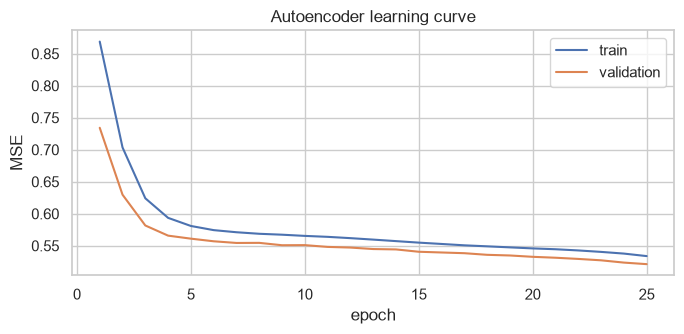

In [17]:
class Autoencoder(nn.Module):
    def __init__(self, n_features, bottleneck=8):
        super().__init__()
        self.encoder = nn.Sequential(nn.Linear(n_features, 16), nn.ReLU(),
                                     nn.Linear(16, bottleneck), nn.ReLU())
        self.decoder = nn.Sequential(nn.Linear(bottleneck, 16), nn.ReLU(),
                                     nn.Linear(16, n_features))
    def forward(self, x):
        return self.decoder(self.encoder(x))

torch.manual_seed(SEED)
X_tr_t = torch.from_numpy(X_train_s)
perm = torch.randperm(len(X_tr_t))
n_val = int(0.1 * len(X_tr_t))
ae_val, ae_train = X_tr_t[perm[:n_val]], X_tr_t[perm[n_val:]]
loader = DataLoader(TensorDataset(ae_train), batch_size=512, shuffle=True)

ae = Autoencoder(X_train_s.shape[1])
optimizer = torch.optim.Adam(ae.parameters(), lr=1e-3)
loss_fn = nn.MSELoss()
EPOCHS = 25
history = {"train": [], "val": []}

t0 = time.time()
for epoch in range(EPOCHS):
    ae.train()
    running = 0.0
    for (xb,) in loader:
        optimizer.zero_grad()
        loss = loss_fn(ae(xb), xb)
        loss.backward()
        optimizer.step()
        running += loss.item() * len(xb)
    ae.eval()
    with torch.no_grad():
        val_loss = loss_fn(ae(ae_val), ae_val).item()
    history["train"].append(running / len(ae_train)); history["val"].append(val_loss)
    if epoch % 5 == 0 or epoch == EPOCHS - 1:
        print(f"epoch {epoch+1:2d}/{EPOCHS}  train MSE {history['train'][-1]:.4f}  val MSE {val_loss:.4f}")
print(f"Training took {time.time()-t0:.0f}s")

plt.figure(figsize=(7, 3.5))
plt.plot(range(1, EPOCHS + 1), history["train"], label="train")
plt.plot(range(1, EPOCHS + 1), history["val"], label="validation")
plt.xlabel("epoch"); plt.ylabel("MSE"); plt.title("Autoencoder learning curve"); plt.legend()
plt.tight_layout(); plt.show()

In [18]:
def reconstruction_error(model, X_np):
    model.eval()
    with torch.no_grad():
        x = torch.from_numpy(X_np)
        return ((model(x) - x) ** 2).mean(dim=1).numpy()

scores["Autoencoder"] = (reconstruction_error(ae, X_train_s), reconstruction_error(ae, X_test_s))

The training and validation curves fall together and flatten out, so the autoencoder **is not overfitting**:
it learned general patterns of normal transactions rather than memorising them.

### 4.4 A simple ensemble
The three models look at the data in different ways (isolation, boundaries, reconstruction).
Their scores live on different scales, so each score is converted into a **percentile rank** (relative to the
training scores), and the three percentiles are averaged. This needs no labels at all.

In [19]:
def to_percentile(train_s, s):
    return np.searchsorted(np.sort(train_s), s) / len(train_s)

base_models = ["Isolation Forest", "One-Class SVM", "Autoencoder"]
ens_train = np.mean([to_percentile(scores[m][0], scores[m][0]) for m in base_models], axis=0)
ens_test = np.mean([to_percentile(scores[m][0], scores[m][1]) for m in base_models], axis=0)
scores["Ensemble"] = (ens_train, ens_test)

## 5. Evaluation: revealing the hidden labels 🔓
Now, and only now, `y_test` is used to grade the models.

**Metrics:**
- **Precision**: of the transactions we flagged, how many were really fraud? (low precision = many false alarms)
- **Recall**: of all real frauds, how many did we catch? (low recall = frauds slip through)
- **F1**: the harmonic mean of precision and recall
- **PR-AUC (average precision)**: summarises precision-recall over *all* thresholds. A random guess scores ≈ the
  fraud rate (0.0017), so this is the most informative single number for imbalanced data.
- **ROC-AUC**: the probability that a random fraud gets a higher score than a random normal transaction. It looks
  optimistic on imbalanced data, so it is reported for completeness.

### 5.1 Threshold-independent comparison

In [20]:
rows = []
for name, (_, s_test) in scores.items():
    rows.append({"Model": name,
                 "ROC-AUC": roc_auc_score(y_test, s_test),
                 "PR-AUC": average_precision_score(y_test, s_test)})
rows.append({"Model": "Random guess (baseline)", "ROC-AUC": 0.5, "PR-AUC": y_test.mean()})
summary = pd.DataFrame(rows).set_index("Model")
summary["PR-AUC lift vs random"] = (summary["PR-AUC"] / y_test.mean()).round(0).astype(int).astype(str) + "x"
summary.style.format({"ROC-AUC": "{:.3f}", "PR-AUC": "{:.3f}"}).background_gradient(subset=["PR-AUC"], cmap="Greens")

,ROC-AUC,PR-AUC,PR-AUC lift vs random
Model,,,
Distance baseline,0.961,0.200,126x
Isolation Forest,0.961,0.253,159x
One-Class SVM,0.956,0.125,79x
Autoencoder,0.899,0.035,22x
Ensemble,0.943,0.076,48x
Random guess (baseline),0.500,0.002,1x


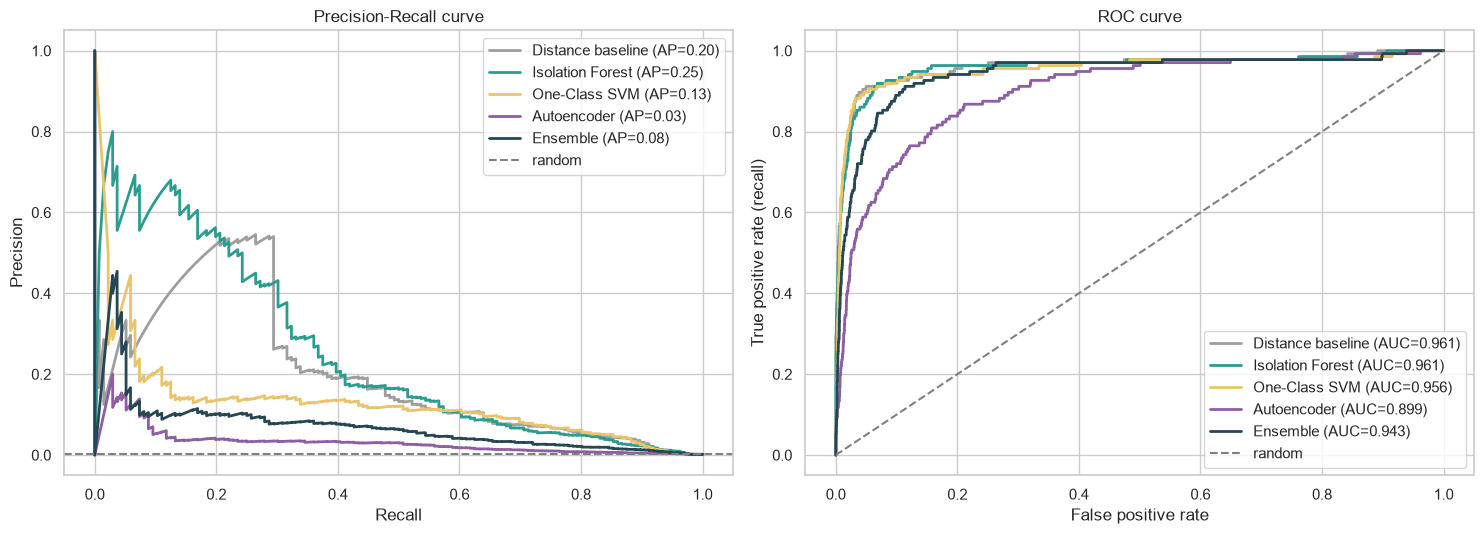

In [21]:
fig, ax = plt.subplots(1, 2, figsize=(15, 5.5))
for name, (_, s_test) in scores.items():
    p, r, _ = precision_recall_curve(y_test, s_test)
    ax[0].plot(r, p, label=f"{name} (AP={average_precision_score(y_test, s_test):.2f})",
               color=MODEL_COLORS[name], lw=2)
    fpr, tpr, _ = roc_curve(y_test, s_test)
    ax[1].plot(fpr, tpr, label=f"{name} (AUC={roc_auc_score(y_test, s_test):.3f})",
               color=MODEL_COLORS[name], lw=2)
ax[0].axhline(y_test.mean(), ls="--", c="grey", label="random")
ax[0].set_xlabel("Recall"); ax[0].set_ylabel("Precision"); ax[0].set_title("Precision-Recall curve")
ax[0].legend()
ax[1].plot([0, 1], [0, 1], ls="--", c="grey", label="random")
ax[1].set_xlabel("False positive rate"); ax[1].set_ylabel("True positive rate (recall)"); ax[1].set_title("ROC curve")
ax[1].legend()
plt.tight_layout(); plt.show()

### 5.2 Performance at the main operating point (flag top 0.2 %)

In [22]:
rows = []
for name, (s_train, s_test) in scores.items():
    pred = flag(s_train, s_test, PRIMARY_BUDGET)
    rows.append({"Model": name, "Flagged": pred.sum(),
                 "Frauds caught": int((pred & y_test).sum()), "Total frauds": int(y_test.sum()),
                 "Precision": precision_score(y_test, pred, zero_division=0),
                 "Recall": recall_score(y_test, pred), "F1": f1_score(y_test, pred)})
primary = pd.DataFrame(rows).set_index("Model")
primary.style.format({"Precision": "{:.3f}", "Recall": "{:.3f}", "F1": "{:.3f}"}) \
       .background_gradient(subset=["F1"], cmap="Greens")

,Flagged,Frauds caught,Total frauds,Precision,Recall,F1
Model,,,,,,
Distance baseline,156,42,136,0.269,0.309,0.288
Isolation Forest,175,49,136,0.280,0.360,0.315
One-Class SVM,184,25,136,0.136,0.184,0.156
Autoencoder,156,12,136,0.077,0.088,0.082
Ensemble,168,15,136,0.089,0.110,0.099


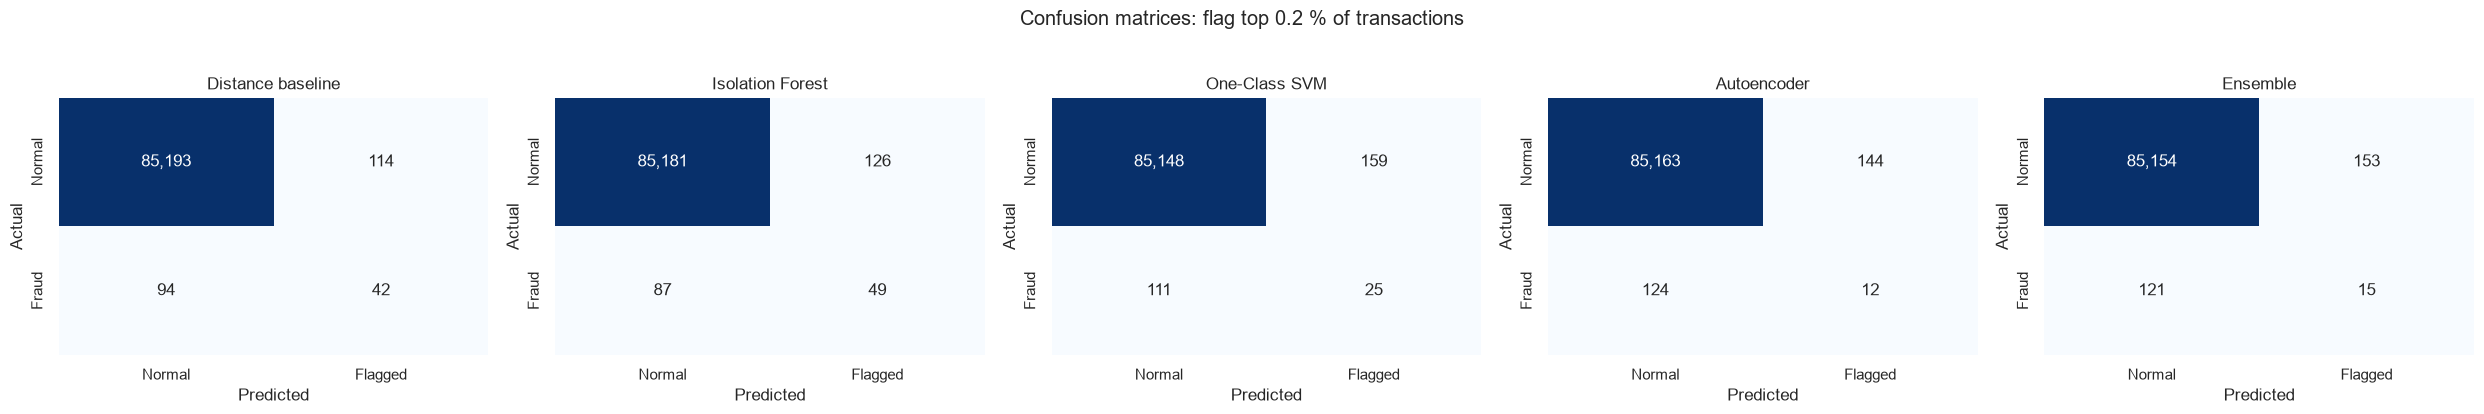

Best model by PR-AUC: Isolation Forest

              precision    recall  f1-score   support

      Normal      0.999     0.999     0.999     85307
       Fraud      0.280     0.360     0.315       136

    accuracy                          0.998     85443
   macro avg      0.639     0.679     0.657     85443
weighted avg      0.998     0.998     0.998     85443



In [23]:
fig, ax = plt.subplots(1, len(scores), figsize=(5 * len(scores), 4))
for a, (name, (s_train, s_test)) in zip(ax, scores.items()):
    cm = confusion_matrix(y_test, flag(s_train, s_test, PRIMARY_BUDGET))
    sns.heatmap(cm, annot=True, fmt=",", cmap="Blues", cbar=False, ax=a,
                xticklabels=["Normal", "Flagged"], yticklabels=["Normal", "Fraud"])
    a.set_title(name); a.set_xlabel("Predicted"); a.set_ylabel("Actual")
plt.suptitle("Confusion matrices: flag top 0.2 % of transactions", y=1.03)
plt.tight_layout(); plt.show()

best_model = summary.drop(["Random guess (baseline)", "Distance baseline"])["PR-AUC"].idxmax()
print(f"Best model by PR-AUC: {best_model}\n")
print(classification_report(y_test, flag(*scores[best_model], PRIMARY_BUDGET),
                            target_names=["Normal", "Fraud"], digits=3))

### 5.3 What if the fraud team can review more (or fewer) transactions?
The alert budget is a business decision. Flagging more transactions catches more fraud (**higher recall**)
but each alert is less likely to be real (**lower precision**). This is the classic trade-off.

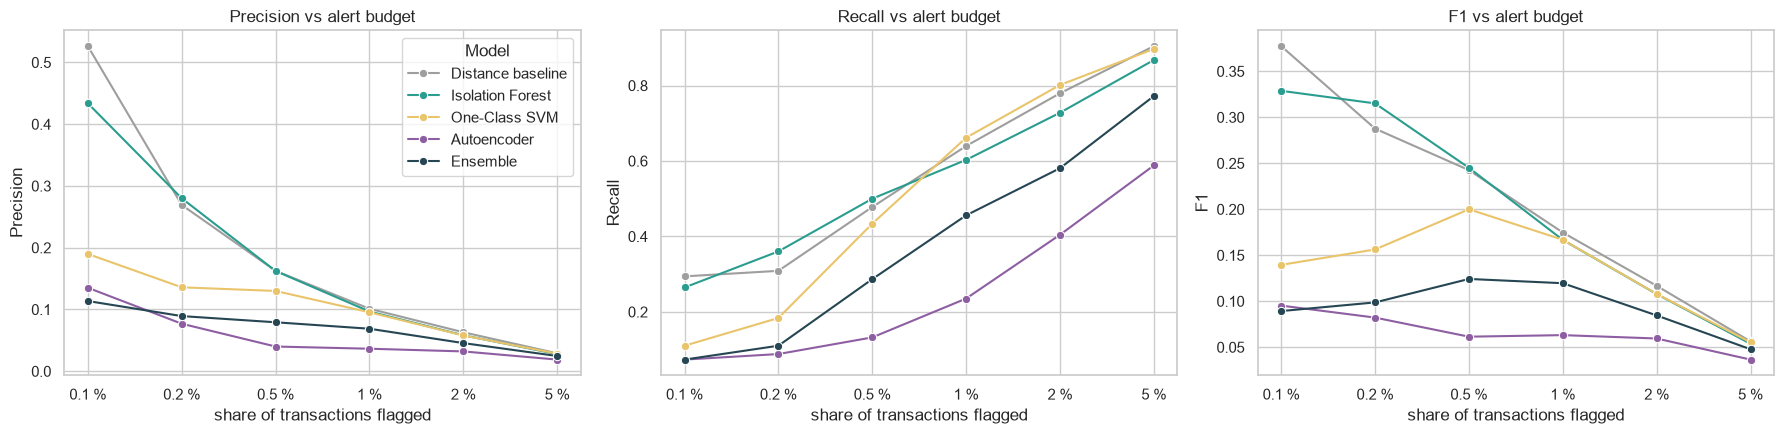

Precision                                    Recall         \
Budget                0.1 %  0.2 %  0.5 %    1 %    2 %    5 %  0.1 %  0.2 %   
Model                                                                          
Autoencoder           0.135  0.077  0.040  0.036  0.032  0.019  0.074  0.088   
Distance baseline     0.526  0.269  0.162  0.101  0.063  0.029  0.294  0.309   
Ensemble              0.114  0.089  0.079  0.069  0.046  0.025  0.074  0.110   
Isolation Forest      0.434  0.280  0.162  0.097  0.058  0.028  0.265  0.360   
One-Class SVM         0.190  0.136  0.130  0.095  0.058  0.029  0.110  0.184   

                                               
Budget             0.5 %    1 %    2 %    5 %  
Model                                          
Autoencoder        0.132  0.235  0.404  0.588  
Distance baseline  0.478  0.640  0.779  0.904  
Ensemble           0.287  0.456  0.581  0.772  
Isolation Forest   0.500  0.603  0.728  0.868  
One-Class SVM      0.434  0.662  0.801  0.897

In [24]:
rows = []
for name, (s_train, s_test) in scores.items():
    for b in BUDGETS:
        pred = flag(s_train, s_test, b)
        rows.append({"Model": name, "Budget": f"{b*100:g} %",
                     "Precision": precision_score(y_test, pred, zero_division=0),
                     "Recall": recall_score(y_test, pred), "F1": f1_score(y_test, pred)})
sweep = pd.DataFrame(rows)

fig, ax = plt.subplots(1, 3, figsize=(18, 4.5))
for a, metric in zip(ax, ["Precision", "Recall", "F1"]):
    sns.lineplot(data=sweep, x="Budget", y=metric, hue="Model", marker="o", ax=a,
                 palette=MODEL_COLORS, sort=False)
    a.set_title(f"{metric} vs alert budget"); a.set_xlabel("share of transactions flagged")
    if a is not ax[0]: a.get_legend().remove()
plt.tight_layout(); plt.show()

sweep.pivot(index="Model", columns="Budget", values=["Precision", "Recall"]) \
     .reindex(columns=[f"{b*100:g} %" for b in BUDGETS], level=1).round(3)

### 5.4 Score distributions: how separated are frauds from normal transactions?

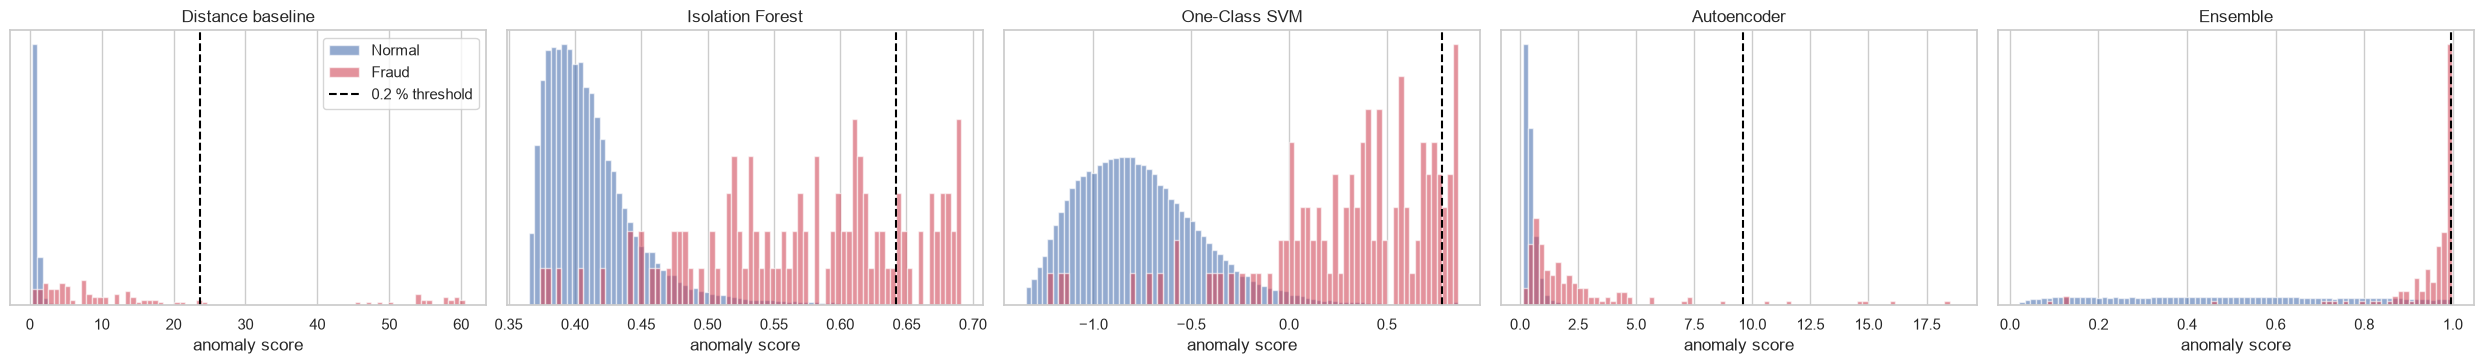

In [25]:
fig, ax = plt.subplots(1, len(scores), figsize=(5 * len(scores), 3.8))
for a, (name, (s_train, s_test)) in zip(ax, scores.items()):
    lo, hi = np.percentile(s_test, [0.5, 99.95])
    bins = np.linspace(lo, hi, 80)
    a.hist(s_test[y_test == 0], bins=bins, density=True, alpha=.6, color=NORMAL_C, label="Normal")
    a.hist(s_test[y_test == 1], bins=bins, density=True, alpha=.6, color=FRAUD_C, label="Fraud")
    a.axvline(np.quantile(s_train, 1 - PRIMARY_BUDGET), c="black", ls="--", label="0.2 % threshold")
    a.set_title(name); a.set_xlabel("anomaly score"); a.set_yticks([])
ax[0].legend()
plt.tight_layout(); plt.show()

For every model, frauds clearly shift towards **higher anomaly scores**, which is the whole point. But there is a
**long overlap**: a sizeable group of frauds gets "normal" scores. No threshold can catch those without also
flagging thousands of legitimate transactions.

### 5.5 Why is the Autoencoder weak here? (diagnostic)
The autoencoder ranks frauds worse than Isolation Forest, and even worse than the naive distance baseline.
To understand why, I separately retrained it with a few other architectures and checked the test PR-AUC.
**This was a diagnostic only. The architecture in the notebook was fixed beforehand and not changed based on these numbers**,
because picking the architecture with the labels would break the unsupervised rule.

| Architecture (hidden → bottleneck) | PR-AUC |
|---|---|
| 16 → 8, ReLU (used above) | ≈ 0.04 |
| 48 → 20, ReLU | 0.05 |
| 16 → 4, ELU | 0.08 |
| 64 → 24, ReLU | 0.09 |
| 32 → 16, ReLU | 0.15 |

**Takeaways**
- The results jump around with no clear pattern. **In a real unsupervised setting we would have no labels to tell us
  which architecture to pick**, so this instability is a real weakness, not just bad luck.
- The deeper reason is that `V1`-`V28` are **already PCA components**: they are uncorrelated, so there is little
  redundancy for an autoencoder to compress. A small bottleneck rebuilds *every* transaction poorly, and that noise
  hides the fraud signal. Autoencoders shine on raw, highly correlated data (images, sensor streams, raw transaction
  fields), which is not what we have here.

## 6. Insights: what got flagged, and why?
Now I take the **best model** at the 0.2 % budget and split the test transactions into four groups:

| Group | Meaning |
|---|---|
| **True positive** | flagged and really fraud ✅ |
| **False positive** | flagged but legitimate (false alarm) |
| **False negative** | fraud the model missed ❌ |
| **True negative** | normal and not flagged |

In [26]:
test_df = df.loc[X_test.index].copy()
test_df["Hour"] = (test_df["Time"] // 3600 % 24).astype(int)
test_df["score"] = scores[best_model][1]
test_df["flagged"] = flag(*scores[best_model], PRIMARY_BUDGET)
fraud, flagged = test_df["Class"] == 1, test_df["flagged"] == 1
test_df["group"] = np.select(
    [flagged & fraud, flagged & ~fraud, ~flagged & fraud],
    ["True positive", "False positive", "False negative"], default="True negative")
group_order = ["True positive", "False positive", "False negative", "True negative"]

profile = test_df.groupby("group").agg(
    n=("Amount", "size"),
    amount_median=("Amount", "median"),
    amount_mean=("Amount", "mean"),
    share_under_2_eur=("Amount", lambda a: (a < 2).mean()),
    share_night_0_6h=("Hour", lambda h: (h < 6).mean()),
).reindex(group_order)
print(f"Model analysed: {best_model}")
profile.style.format({"amount_median": "€{:.2f}", "amount_mean": "€{:.2f}",
                      "share_under_2_eur": "{:.0%}", "share_night_0_6h": "{:.0%}"})

Model analysed: Isolation Forest


,n,amount_median,amount_mean,share_under_2_eur,share_night_0_6h
group,,,,,
True positive,49,€11.38,€108.44,41%,45%
False positive,126,€138.90,€1103.26,21%,9%
False negative,87,€8.30,€163.91,37%,11%
True negative,85181,€22.00,€85.71,16%,8%


**What do the four groups look like?** (Isolation Forest, 0.2 % budget)

| | Caught frauds (TP) | False alarms (FP) | Missed frauds (FN) | Normal (TN) |
|---|---|---|---|---|
| Median amount | **€11** | **€139** | €8 | €22 |
| Share under €2 | **41 %** | 21 % | 37 % | 16 % |
| Share at night (0-6 h) | **45 %** | 9 % | 11 % | 8 % |

- **Caught frauds** are mostly **small amounts at night**. Many are under €2, which looks like *card testing*
  (fraudsters checking that a stolen card works before using it for bigger purchases).
- **False alarms** are mostly **unusually large legitimate purchases** (mean ≈ €1,100). Isolation Forest finds
  *unusual* transactions, and a €3,000 purchase is unusual even when it is honest.
- **Missed frauds** happen during the day and look like normal purchases. They are frauds that blend in.

### 6.1 Which features make a transaction look anomalous?

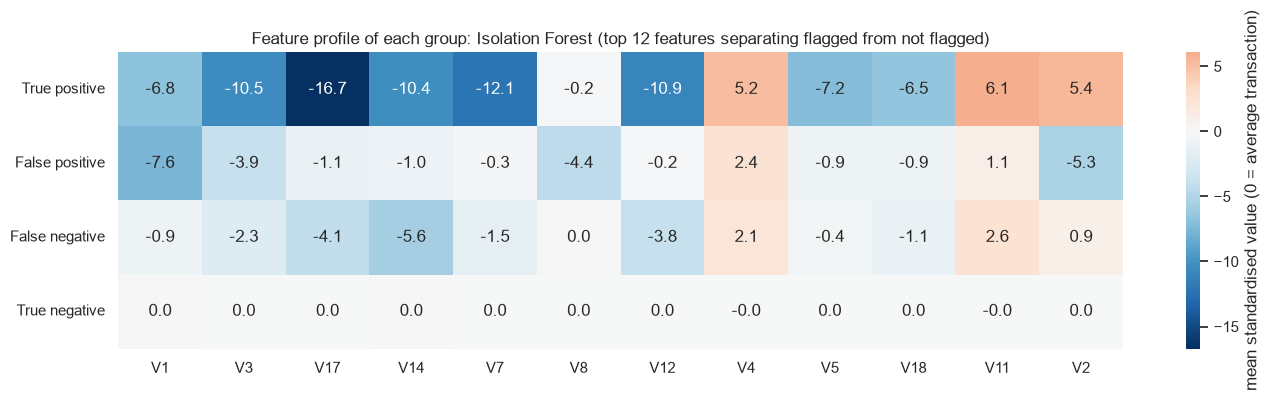

In [27]:
Z = pd.DataFrame(X_test_s, columns=feature_names, index=X_test.index)
Z["group"] = test_df["group"]
group_means = Z.groupby("group")[feature_names].mean().reindex(group_order)

# features that differ most between flagged and non-flagged transactions
diff = (Z.loc[flagged, feature_names].mean() - Z.loc[~flagged, feature_names].mean()).abs()
top_feats = diff.sort_values(ascending=False).head(12).index.tolist()

plt.figure(figsize=(14, 3.8))
sns.heatmap(group_means[top_feats], annot=True, fmt=".1f", cmap="RdBu_r", center=0,
            cbar_kws={"label": "mean standardised value (0 = average transaction)"})
plt.title(f"Feature profile of each group: {best_model} (top 12 features separating flagged from not flagged)")
plt.ylabel(""); plt.tight_layout(); plt.show()

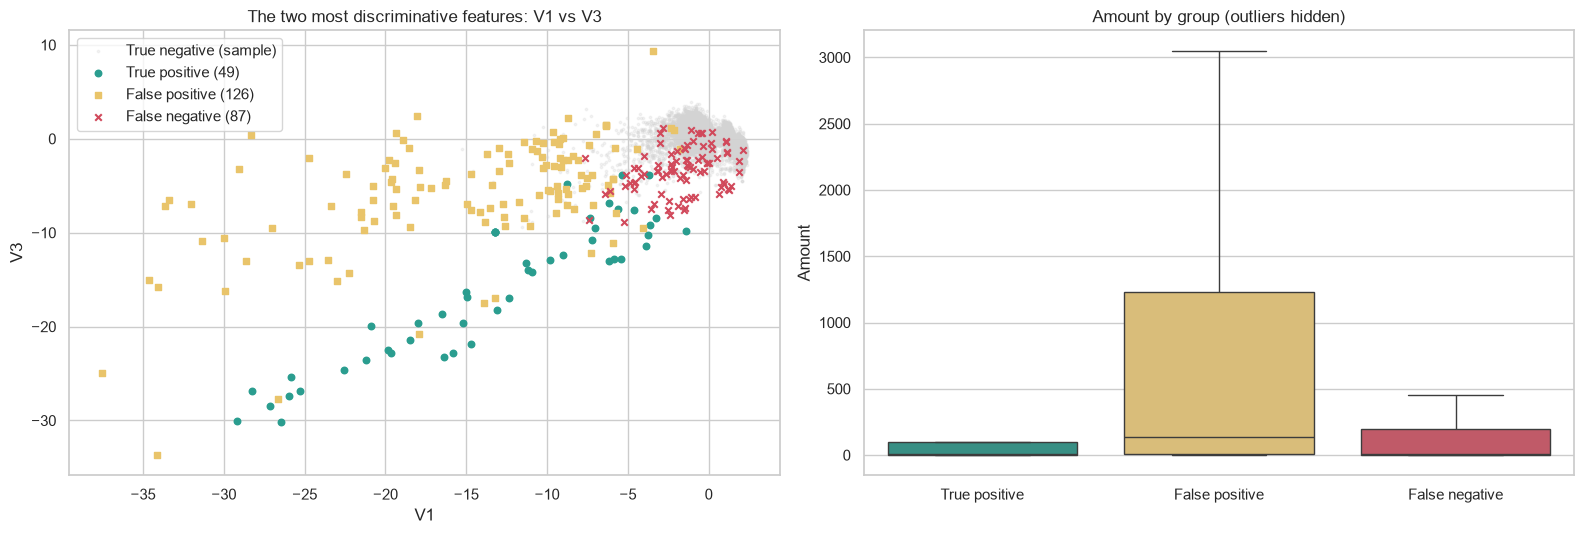

In [28]:
f1_, f2_ = top_feats[:2]
fig, ax = plt.subplots(1, 2, figsize=(16, 5.5))
bg = test_df[test_df["group"] == "True negative"].sample(8000, random_state=SEED)
ax[0].scatter(bg[f1_], bg[f2_], s=3, alpha=.25, c="lightgrey", label="True negative (sample)")
styles = {"True positive": ("#2A9D8F", "o"), "False positive": ("#E9C46A", "s"), "False negative": (FRAUD_C, "x")}
for g, (c, m) in styles.items():
    d = test_df[test_df["group"] == g]
    ax[0].scatter(d[f1_], d[f2_], s=22, c=c, marker=m, label=f"{g} ({len(d)})")
ax[0].set_xlabel(f1_); ax[0].set_ylabel(f2_); ax[0].legend()
ax[0].set_title(f"The two most discriminative features: {f1_} vs {f2_}")

sns.boxplot(data=test_df[test_df["group"] != "True negative"], x="group", y="Amount",
            order=group_order[:3], palette=[styles[g][0] for g in group_order[:3]], ax=ax[1], showfliers=False)
ax[1].set_title("Amount by group (outliers hidden)"); ax[1].set_xlabel("")
plt.tight_layout(); plt.show()

**Reading the heatmap and scatter plot**
- **Caught frauds are extreme on a consistent set of features**: very negative `V17` (−16.7 standard deviations!),
  `V7`, `V12`, `V3`, `V14`, `V5`, `V18` and very positive `V4`, `V11`, `V2`. This is a coherent *fraud signature*:
  in the `V1`-`V3` scatter, the caught frauds line up along their own diagonal "arm", far away from the normal cloud.
- **False alarms are extreme on *different* features**: mainly very negative `V1`, `V2` and `V8`. `V2` and `V7`
  are the features most correlated with `Amount` (see the correlation heatmap), which confirms that these are the
  *big purchases*. They are anomalous in a different direction from fraud.
- **Missed frauds point in the same direction as caught frauds** (negative `V14`, `V17`, `V12`, positive `V11`, `V4`)
  but much more weakly (−4 to −6 instead of −10 to −17). They sit on the edge of the normal cloud, close enough to be
  hidden among thousands of legitimate transactions.

👉 **Key insight:** the models detect *"different"*, not *"fraudulent"*. Fraud and "different" overlap a lot,
but not completely.

### 6.2 Do the models agree on which frauds they catch?

In [29]:
caught = pd.DataFrame({m: flag(*scores[m], PRIMARY_BUDGET)[y_test == 1].astype(bool) for m in base_models})
n_models = caught.sum(axis=1)
print(f"Frauds in test set: {len(caught)}")
for k in range(4):
    print(f"  caught by exactly {k} of the 3 models: {(n_models == k).sum():3d}")
print("\nPairwise overlap of caught frauds:")
print(pd.DataFrame({a: {b: int((caught[a] & caught[b]).sum()) for b in base_models} for a in base_models}))

Frauds in test set: 136
  caught by exactly 0 of the 3 models:  83
  caught by exactly 1 of the 3 models:  27
  caught by exactly 2 of the 3 models:  19
  caught by exactly 3 of the 3 models:   7

Pairwise overlap of caught frauds:
                  Isolation Forest  One-Class SVM  Autoencoder
Isolation Forest                49             21           12
One-Class SVM                   21             25            7
Autoencoder                     12              7           12


- At the 0.2 % budget, **83 of the 136 test frauds (61 %) are missed by all three models**, and only 7 are caught by all three.
- The models partly catch **different** frauds: together they catch 53, while the best single model catches 49.
  Almost all of One-Class SVM's catches (21 of 25) are also caught by Isolation Forest.
- This explains why the **averaging ensemble did worse** than Isolation Forest. Averaging percentiles only scores a
  transaction highly when *all* models agree, so the weak autoencoder dilutes the strong signal from Isolation Forest.
  A better combination rule (e.g. taking the maximum score) or dropping weak members would be worth trying, but
  without labels it is hard to know in advance which members are weak.

## 7. Conclusions

### What worked
1. **Unsupervised anomaly detection does find fraud without any labels.** The best model, **Isolation Forest**, reached a
   **PR-AUC of 0.25, about 160× better than random guessing** (0.0016), and a ROC-AUC of 0.96.
2. **At a review budget of 0.2 %** (175 alerts out of 85,443 test transactions), Isolation Forest caught
   **49 of 136 frauds: precision 28 %, recall 36 %, F1 0.32**. An alert is about **175× more likely to be fraud** than a
   random transaction.
3. **Recall grows quickly with the budget**: flagging 1 % of transactions catches ~60 % of frauds, and 5 % catches ~87 %.
   At these larger budgets **One-Class SVM is slightly better** (66 % recall at 1 %, 80 % at 2 %). So the best model
   depends on how many alerts the fraud team can handle.

### Model ranking (by PR-AUC)
| Model | PR-AUC | Comment |
|---|---|---|
| **Isolation Forest** | **0.25** | best overall, fast (~12 s), no tuning needed |
| Distance baseline | 0.20 | surprisingly strong: fraud ≈ "extreme values" |
| One-Class SVM | 0.13 | strong at larger budgets, slow (trained on a 20k subsample) |
| Ensemble (average) | 0.08 | dragged down by the weakest member |
| Autoencoder | 0.04 | unstable; little redundancy to compress in PCA features |

### Patterns in the detected anomalies
- **Detected frauds** are typically **small amounts (often < €2), at night**, with extreme values in `V17`, `V14`, `V12`,
  `V7`, `V3` (very negative) and `V4`, `V11` (very positive). That looks like card testing and automated fraud.
- **False alarms** are mainly **large, legitimate purchases**: unusual, but not fraudulent.
- **Missed frauds** look like ordinary daytime purchases with only mildly unusual feature values.

### Limitations
- **Anomaly ≠ fraud.** About 60 % of frauds are *not* anomalous enough to stand out, and many anomalies are honest.
  This is the fundamental ceiling of a purely unsupervised approach.
- The **decision threshold** (0.2 % budget) is an assumption from domain knowledge. In practice it is set by business capacity.
- **Hyperparameters cannot be validated** without labels. The autoencoder diagnostic (Section 5.5) shows how much this can matter.
- Features are anonymised PCA components, so we can say *which* components matter but not what they mean in business terms.
- The data covers only **two days**, so weekly or seasonal patterns cannot be checked.

### Next steps
- Use the few confirmed frauds that a bank does have: a **semi-supervised** setup (e.g. train the autoencoder on
  verified-normal transactions only), or a supervised model (e.g. gradient boosting) once enough labels exist.
- Try other unsupervised detectors (Local Outlier Factor, ECOD) and smarter ensembles (max score, or excluding weak members).
- Add behavioural features (spending history per card, time since the last transaction) that would make fraud stand out
  more. They are not available in this anonymised dataset.
- Put a **human-in-the-loop** around it: analysts review the alerts, and their decisions become labels that improve the model over time.